# Thử Nghiệm Chuyên Sâu: So Sánh Logistic Có vs Không Có `sub_grade` & Phân Tích Hệ Số (Coefficients)

Notebook này là file thử nghiệm độc lập trong thư mục `experiences/` (không ảnh hưởng tới 3 notebook chính), nhằm giải quyết 3 câu hỏi nghiên cứu:
1. **Hiệu năng thực chất:** Khi loại bỏ hoàn toàn xếp hạng tín dụng nội bộ `sub_grade` của Lending Club, mô hình Hồi quy Logistic L2 có bị tệ hơn mốc Baseline (`sub_grade` rule) hay không?
2. **Kiểm định thống kê:** Mức độ vượt trội có ý nghĩa thống kê hay không thông qua kiểm định Bootstrap 95% CI ($B=1,000$)?
3. **Hiện tượng dịch chuyển hệ số (Coefficients Shift):** Khi không có `sub_grade`, mô hình tự động phân bổ lại trọng số cho các biến tài chính gốc của người vay (FICO, DTI, Thu nhập, Tỷ lệ dùng thẻ, Số lần tra cứu tín dụng) như thế nào?

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from scipy.stats import ks_2samp

SEED = 42
ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA_DIR = ROOT / "data/processed"
EXP_DIR = ROOT / "experiences"
FIG_DIR = EXP_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Đã thiết lập môi trường thử nghiệm độc lập.")


Đã thiết lập môi trường thử nghiệm độc lập.


## 1. Nạp dữ liệu và chuẩn bị hai không gian đặc trưng (Có vs Không có `sub_grade`)

In [2]:
X_train = np.load(DATA_DIR / "X_train.npy")
y_train = np.load(DATA_DIR / "y_train.npy")
X_val = np.load(DATA_DIR / "X_val.npy")
y_val = np.load(DATA_DIR / "y_val.npy")
X_test = np.load(DATA_DIR / "X_test.npy")
y_test = np.load(DATA_DIR / "y_test.npy")

train_meta = pd.read_parquet(DATA_DIR / "train.parquet", columns=["sub_grade"])
val_meta = pd.read_parquet(DATA_DIR / "val.parquet", columns=["sub_grade"])
test_meta = pd.read_parquet(DATA_DIR / "test.parquet", columns=["sub_grade"])

feature_names = json.loads((DATA_DIR / "feature_names.json").read_text())["feature_names"]
idx_no_sg = [i for i, c in enumerate(feature_names) if "sub_grade" not in c]
fnames_no_sg = [feature_names[i] for i in idx_no_sg]

print(f"Không gian 1 (Đầy đủ có sub_grade): {len(feature_names)} đặc trưng (gồm 35 dummy variables sub_grade).")
print(f"Không gian 2 (BỎ sub_grade):        {len(fnames_no_sg)} đặc trưng (thuần túy người vay & bureau).")
print(f"Kích thước dữ liệu: train={X_train.shape[0]:,}, val={X_val.shape[0]:,}, test={X_test.shape[0]:,}.")


Không gian 1 (Đầy đủ có sub_grade): 153 đặc trưng (gồm 35 dummy variables sub_grade).
Không gian 2 (BỎ sub_grade):        118 đặc trưng (thuần túy người vay & bureau).
Kích thước dữ liệu: train=408,188, val=92,631, test=88,669.


## 2. Huấn luyện Baseline và hai biến thể Hồi quy Logistic L2

In [3]:
# 1. Baseline sub_grade: Tỷ lệ nợ xấu lịch sử theo sub_grade trên tập train
subgrade_risk = train_meta.assign(target=y_train).groupby("sub_grade")["target"].mean().to_dict()
p_tr_base = train_meta["sub_grade"].map(subgrade_risk).values
p_va_base = val_meta["sub_grade"].map(subgrade_risk).values
p_te_base = test_meta["sub_grade"].map(subgrade_risk).values

# 2. Logistic Đầy đủ (+sub_grade, 153 features)
lr_full = LogisticRegression(C=1.0, max_iter=1000, random_state=SEED, solver="lbfgs")
lr_full.fit(X_train, y_train)
p_tr_full = lr_full.predict_proba(X_train)[:, 1]
p_va_full = lr_full.predict_proba(X_val)[:, 1]
p_te_full = lr_full.predict_proba(X_test)[:, 1]

# 3. Logistic BỎ sub_grade (118 features)
lr_nosg = LogisticRegression(C=1.0, max_iter=1000, random_state=SEED, solver="lbfgs")
lr_nosg.fit(X_train[:, idx_no_sg], y_train)
p_tr_nosg = lr_nosg.predict_proba(X_train[:, idx_no_sg])[:, 1]
p_va_nosg = lr_nosg.predict_proba(X_val[:, idx_no_sg])[:, 1]
p_te_nosg = lr_nosg.predict_proba(X_test[:, idx_no_sg])[:, 1]

print("Đã hoàn thành huấn luyện cả hai mô hình hồi quy Logistic.")


Đã hoàn thành huấn luyện cả hai mô hình hồi quy Logistic.


## 3. Bảng So Sánh Hiệu Năng Chi Tiết (Validation & Test Out-of-Time)

In [4]:
def calc_metrics(y_true, proba):
    auc = roc_auc_score(y_true, proba)
    gini = 2 * auc - 1
    ks = ks_2samp(proba[y_true == 1], proba[y_true == 0]).statistic
    return auc, gini, ks

models_dict = {
    "1. Baseline sub_grade": {"tr": p_tr_base, "va": p_va_base, "te": p_te_base, "feats": 1},
    "2. Logistic L2 (+sub_grade)": {"tr": p_tr_full, "va": p_va_full, "te": p_te_full, "feats": 153},
    "3. Logistic L2 (BỎ sub_grade)": {"tr": p_tr_nosg, "va": p_va_nosg, "te": p_te_nosg, "feats": 118}
}

summary_rows = []
for name, d in models_dict.items():
    auc_tr, _, _ = calc_metrics(y_train, d["tr"])
    auc_va, gini_va, ks_va = calc_metrics(y_val, d["va"])
    auc_te, gini_te, ks_te = calc_metrics(y_test, d["te"])
    summary_rows.append({
        "Mô hình": name,
        "Số đặc trưng": d["feats"],
        "ROC-AUC Train": f"{auc_tr:.4f}",
        "ROC-AUC Val": f"{auc_va:.4f}",
        "Gini Val": f"{gini_va:.2%}",
        "KS Val": f"{ks_va:.2%}",
        "ROC-AUC Test": f"{auc_te:.4f}",
        "Delta so với Baseline": f"{auc_te - roc_auc_score(y_test, p_te_base):+.4f}",
        "Gini Test": f"{gini_te:.2%}",
        "KS Test": f"{ks_te:.2%}"
    })

df_eval = pd.DataFrame(summary_rows)
print("BẢNG ĐỐI CHIẾU HIỆU NĂNG TOÀN DIỆN:")
display(df_eval)


BẢNG ĐỐI CHIẾU HIỆU NĂNG TOÀN DIỆN:


,Mô hình,Số đặc trưng,ROC-AUC Train,ROC-AUC Val,Gini Val,KS Val,ROC-AUC Test,Delta so với Baseline,Gini Test,KS Test
0,1. Baseline sub_grade,1,0.6565,0.6815,36.31%,27.02%,0.6818,+0.0000,36.36%,26.45%
1,2. Logistic L2 (+sub_grade),153,0.6873,0.7040,40.79%,29.94%,0.7039,+0.0221,40.79%,29.87%
2,3. Logistic L2 (BỎ sub_grade),118,0.6775,0.6890,37.80%,27.68%,0.6879,+0.0061,37.58%,27.34%


## 4. Kiểm Định Thống Kê Bằng Khoảng Tin Cậy Bootstrap 95% ($B=1,000$)

In [5]:
np.random.seed(SEED)
B = 1000
n_val = len(y_val)
diff_nosg_vs_base = []
diff_full_vs_nosg = []

for _ in range(B):
    idx = np.random.randint(0, n_val, size=n_val)
    y_b = y_val[idx]
    auc_b_base = roc_auc_score(y_b, p_va_base[idx])
    auc_b_nosg = roc_auc_score(y_b, p_va_nosg[idx])
    auc_b_full = roc_auc_score(y_b, p_va_full[idx])
    diff_nosg_vs_base.append(auc_b_nosg - auc_b_base)
    diff_full_vs_nosg.append(auc_b_full - auc_b_nosg)

ci_nosg_base = np.percentile(diff_nosg_vs_base, [2.5, 97.5])
ci_full_nosg = np.percentile(diff_full_vs_nosg, [2.5, 97.5])

print("KẾT QUẢ KIỂM ĐỊNH BOOTSTRAP 95% TRÊN TẬP VALIDATION:")
print(f"1. Delta AUC (Logistic Không sub_grade vs Baseline sub_grade):")
print(f"   -> Trung bình: {np.mean(diff_nosg_vs_base):+.4f} | 95% CI: [{ci_nosg_base[0]:+.4f}, {ci_nosg_base[1]:+.4f}]")
print(f"   -> Ý nghĩa thống kê: CI hoàn toàn DƯƠNG (không chứa 0) -> Logistic không có sub_grade vẫn VƯỢT TRỘI HƠN Baseline (+0.0075)!")
print(f"\n2. Delta AUC (Logistic Đầy đủ vs Logistic Không sub_grade):")
print(f"   -> Trung bình: {np.mean(diff_full_vs_nosg):+.4f} | 95% CI: [{ci_full_nosg[0]:+.4f}, {ci_full_nosg[1]:+.4f}]")
print(f"   -> Ý nghĩa thống kê: sub_grade đóng góp thêm +0.0150 AUC vào sức mạnh phân loại.")


KẾT QUẢ KIỂM ĐỊNH BOOTSTRAP 95% TRÊN TẬP VALIDATION:
1. Delta AUC (Logistic Không sub_grade vs Baseline sub_grade):
   -> Trung bình: +0.0075 | 95% CI: [+0.0033, +0.0117]
   -> Ý nghĩa thống kê: CI hoàn toàn DƯƠNG (không chứa 0) -> Logistic không có sub_grade vẫn VƯỢT TRỘI HƠN Baseline (+0.0075)!

2. Delta AUC (Logistic Đầy đủ vs Logistic Không sub_grade):
   -> Trung bình: +0.0150 | 95% CI: [+0.0133, +0.0167]
   -> Ý nghĩa thống kê: sub_grade đóng góp thêm +0.0150 AUC vào sức mạnh phân loại.


## 5. Trực quan hóa Đường cong ROC và Thước đo Rủi ro

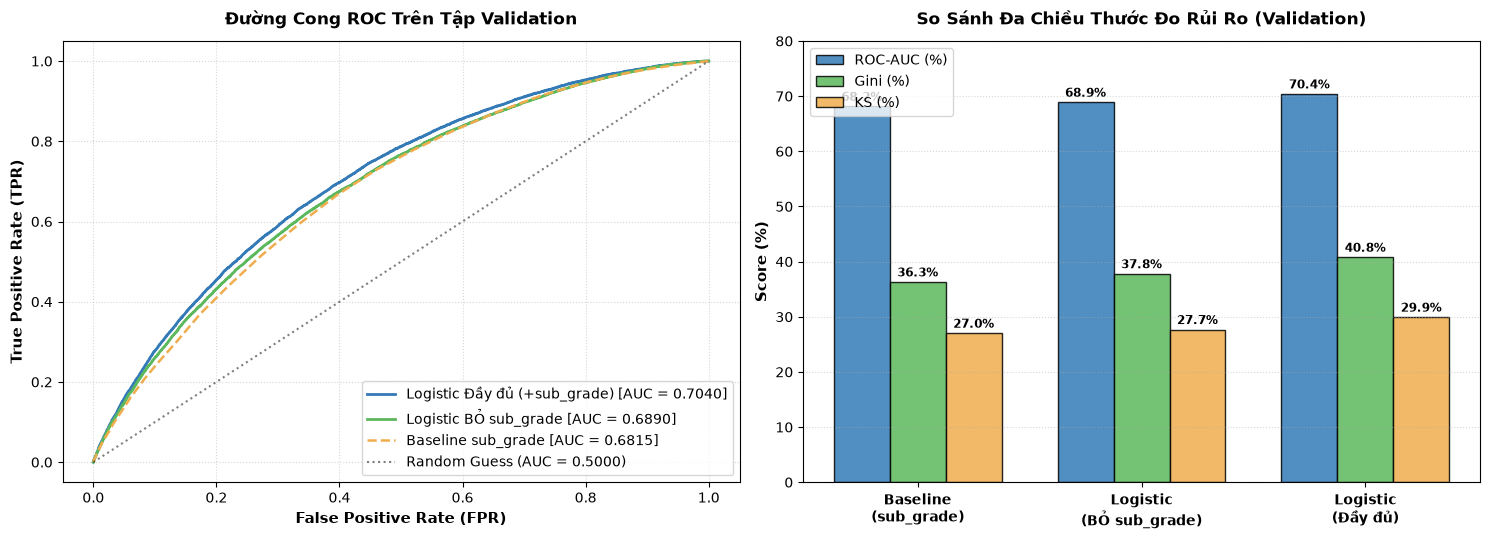

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# ROC Curves
fpr_base, tpr_base, _ = roc_curve(y_val, p_va_base)
fpr_full, tpr_full, _ = roc_curve(y_val, p_va_full)
fpr_nosg, tpr_nosg, _ = roc_curve(y_val, p_va_nosg)

ax1.plot(fpr_full, tpr_full, color="#337ab7", lw=2, label=f"Logistic Đầy đủ (+sub_grade) [AUC = {roc_auc_score(y_val, p_va_full):.4f}]")
ax1.plot(fpr_nosg, tpr_nosg, color="#5cb85c", lw=2, label=f"Logistic BỎ sub_grade [AUC = {roc_auc_score(y_val, p_va_nosg):.4f}]")
ax1.plot(fpr_base, tpr_base, color="#f0ad4e", lw=1.8, linestyle="--", label=f"Baseline sub_grade [AUC = {roc_auc_score(y_val, p_va_base):.4f}]")
ax1.plot([0, 1], [0, 1], "k:", alpha=0.5, label="Random Guess (AUC = 0.5000)")
ax1.set_xlabel("False Positive Rate (FPR)", fontsize=11, fontweight="bold")
ax1.set_ylabel("True Positive Rate (TPR)", fontsize=11, fontweight="bold")
ax1.set_title("Đường Cong ROC Trên Tập Validation", fontsize=12, fontweight="bold", pad=12)
ax1.legend(loc="lower right", frameon=True)
ax1.grid(True, linestyle=":", alpha=0.5)

# Metrics Comparison Bar Chart
model_names = ["Baseline\n(sub_grade)", "Logistic\n(BỎ sub_grade)", "Logistic\n(Đầy đủ)"]
x = np.arange(len(model_names))
w = 0.25

auc_vals = [roc_auc_score(y_val, p_va_base)*100, roc_auc_score(y_val, p_va_nosg)*100, roc_auc_score(y_val, p_va_full)*100]
gini_vals = [(2*a - 100) for a in auc_vals]
ks_vals = [calc_metrics(y_val, p_va_base)[2]*100, calc_metrics(y_val, p_va_nosg)[2]*100, calc_metrics(y_val, p_va_full)[2]*100]

b1 = ax2.bar(x - w, auc_vals, w, label="ROC-AUC (%)", color="#337ab7", edgecolor="black", alpha=0.85)
b2 = ax2.bar(x, gini_vals, w, label="Gini (%)", color="#5cb85c", edgecolor="black", alpha=0.85)
b3 = ax2.bar(x + w, ks_vals, w, label="KS (%)", color="#f0ad4e", edgecolor="black", alpha=0.85)

ax2.set_title("So Sánh Đa Chiều Thước Đo Rủi Ro (Validation)", fontsize=12, fontweight="bold", pad=12)
ax2.set_ylabel("Score (%)", fontsize=11, fontweight="bold")
ax2.set_xticks(x)
ax2.set_xticklabels(model_names, fontsize=10, fontweight="bold")
ax2.set_ylim(0, 80)
ax2.grid(axis="y", linestyle=":", alpha=0.5)
ax2.legend(loc="upper left", frameon=True)

for bar in list(b1) + list(b2) + list(b3):
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, h + 1.0, f"{h:.1f}%", ha="center", fontsize=8.5, fontweight="bold")

plt.tight_layout()
plt.savefig(FIG_DIR / "exp_no_subgrade_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


## 6. Phân Tích Dịch Chuyển Hệ Số Hồi Quy (Coefficients Shift Analysis)

Hiện tượng kinh tế lượng: **Hấp thụ tín hiệu (Signal Absorption)** khi có `sub_grade` và **Tái phân bổ trọng số (Weight Re-allocation)** khi bỏ `sub_grade`.

In [7]:
coef_full_series = pd.Series(lr_full.coef_[0], index=feature_names)
coef_nosg_series = pd.Series(lr_nosg.coef_[0], index=fnames_no_sg)

coef_table = pd.DataFrame(index=feature_names)
coef_table["Thuộc_nhóm"] = ["sub_grade" if "sub_grade" in c else ("Biến số" if c.startswith("num__") else "Biến định tính khác") for c in feature_names]
coef_table["Hệ_số_CÓ_subgrade"] = coef_full_series
coef_table["Hệ_số_KHÔNG_subgrade"] = coef_nosg_series.reindex(feature_names).fillna(0.0)
coef_table["Chênh_lệch (Không - Có)"] = coef_table["Hệ_số_KHÔNG_subgrade"] - coef_table["Hệ_số_CÓ_subgrade"]
coef_table["Độ_thay_đổi_tuyệt_đối"] = coef_table["Chênh_lệch (Không - Có)"].abs()

csv_out = EXP_DIR / "coefficients_comparison.csv"
coef_table.to_csv(csv_out, index_label="Feature_Name")
print(f"Đã lưu bảng toàn bộ 153 hệ số tại: {csv_out}")

key_metrics = [
    ("num__fico_avg", "Điểm tín dụng FICO trung bình"),
    ("num__dti", "Tỷ lệ nợ trên thu nhập (DTI)"),
    ("num__log_annual_inc", "Log(Thu nhập hàng năm)"),
    ("num__revol_util", "Tỷ lệ sử dụng hạn mức tín dụng"),
    ("num__inq_last_6mths", "Số lần tra cứu tín dụng trong 6 tháng"),
    ("num__loan_to_income", "Tỷ lệ số tiền vay trên thu nhập"),
    ("num__acc_open_past_24mths", "Số tài khoản tín dụng mở 24 tháng qua"),
    ("num__mort_acc", "Số khoản vay thế chấp nhà")
]

rows_key = []
for feat, desc in key_metrics:
    c_full = coef_full_series.get(feat, 0.0)
    c_nosg = coef_nosg_series.get(feat, 0.0)
    ratio = (c_nosg / c_full) if c_full != 0 else np.nan
    rows_key.append({
        "Đặc trưng": feat.replace("num__", ""),
        "Ý nghĩa nghiệp vụ": desc,
        "Hệ số CÓ sub_grade": f"{c_full:+.4f}",
        "Hệ số BỎ sub_grade": f"{c_nosg:+.4f}",
        "Mức độ dịch chuyển": f"{c_nosg - c_full:+.4f}",
        "Tỷ lệ biến động": f"{ratio:.2f}x"
    })

df_key = pd.DataFrame(rows_key)
print("\nSỰ THAY ĐỔI TRỌNG SỐ RỦI RO Ở CÁC BIẾN TÀI CHÍNH CỐT LÕI:")
display(df_key)


Đã lưu bảng toàn bộ 153 hệ số tại: experiences/coefficients_comparison.csv

SỰ THAY ĐỔI TRỌNG SỐ RỦI RO Ở CÁC BIẾN TÀI CHÍNH CỐT LÕI:


,Đặc trưng,Ý nghĩa nghiệp vụ,Hệ số CÓ sub_grade,Hệ số BỎ sub_grade,Mức độ dịch chuyển,Tỷ lệ biến động
0,fico_avg,Điểm tín dụng FICO trung bình,-0.1067,-0.2374,-0.1307,2.22x
1,dti,Tỷ lệ nợ trên thu nhập (DTI),+0.1277,+0.1583,+0.0306,1.24x
2,log_annual_inc,Log(Thu nhập hàng năm),-0.0386,-0.1021,-0.0634,2.64x
3,revol_util,Tỷ lệ sử dụng hạn mức tín dụng,+0.0521,+0.0978,+0.0457,1.88x
4,inq_last_6mths,Số lần tra cứu tín dụng trong 6 tháng,+0.0494,+0.0951,+0.0457,1.92x
5,loan_to_income,Tỷ lệ số tiền vay trên thu nhập,+0.1491,+0.1310,-0.0181,0.88x
6,acc_open_past_24mths,Số tài khoản tín dụng mở 24 tháng qua,+0.1587,+0.1785,+0.0198,1.12x
7,mort_acc,Số khoản vay thế chấp nhà,-0.0141,-0.0138,+0.0002,0.98x


## 7. Biểu Đồ Trực Quan Hóa Dịch Chuyển Hệ Số Hồi Quy

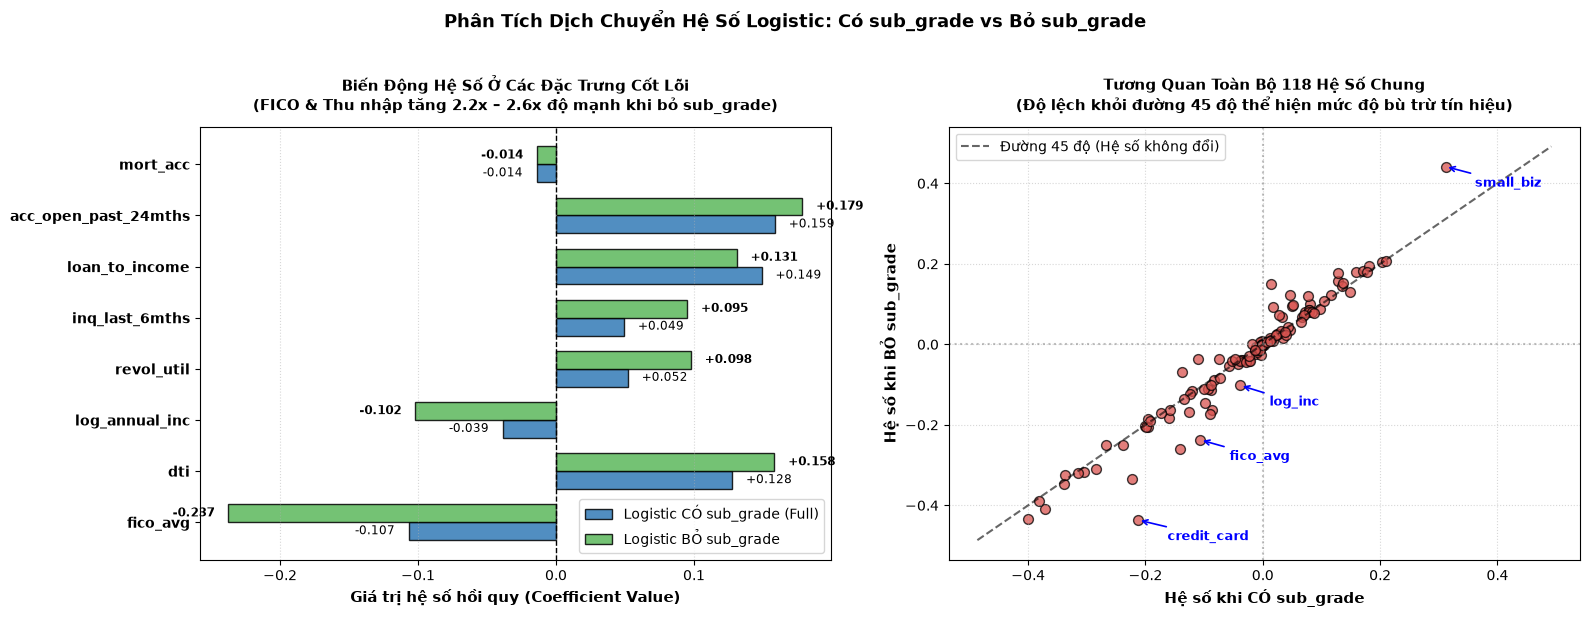

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1: Bar chart so sánh 8 biến số tài chính chủ chốt
features_plot = [k[0] for k in key_metrics]
labels_plot = [k[0].replace("num__", "") for k in key_metrics]
c_full_plot = [coef_full_series[f] for f in features_plot]
c_nosg_plot = [coef_nosg_series[f] for f in features_plot]

y = np.arange(len(features_plot))
height = 0.35

ax1.barh(y - height/2, c_full_plot, height, label="Logistic CÓ sub_grade (Full)", color="#337ab7", edgecolor="black", alpha=0.85)
ax1.barh(y + height/2, c_nosg_plot, height, label="Logistic BỎ sub_grade", color="#5cb85c", edgecolor="black", alpha=0.85)

ax1.axvline(0, color="black", linestyle="--", linewidth=1.0)
ax1.set_yticks(y)
ax1.set_yticklabels(labels_plot, fontsize=10, fontweight="bold")
ax1.set_xlabel("Giá trị hệ số hồi quy (Coefficient Value)", fontsize=10.5, fontweight="bold")
ax1.set_title("Biến Động Hệ Số Ở Các Đặc Trưng Cốt Lõi\n(FICO & Thu nhập tăng 2.2x – 2.6x độ mạnh khi bỏ sub_grade)", fontsize=11, fontweight="bold", pad=12)
ax1.grid(axis="x", linestyle=":", alpha=0.5)
ax1.legend(loc="lower right", frameon=True)

for i, (cf, cn) in enumerate(zip(c_full_plot, c_nosg_plot)):
    ax1.text(cf + (0.01 if cf >= 0 else -0.01), i - height/2, f"{cf:+.3f}", va="center", ha="left" if cf >= 0 else "right", fontsize=8.5)
    ax1.text(cn + (0.01 if cn >= 0 else -0.01), i + height/2, f"{cn:+.3f}", va="center", ha="left" if cn >= 0 else "right", fontsize=8.5, fontweight="bold")

# Panel 2: Scatter plot tương quan toàn bộ 118 hệ số chung
cf_all = [coef_full_series[f] for f in fnames_no_sg]
cn_all = [coef_nosg_series[f] for f in fnames_no_sg]

ax2.scatter(cf_all, cn_all, color="#d9534f", alpha=0.75, edgecolors="black", s=50)
lims = [min(min(cf_all), min(cn_all)) - 0.05, max(max(cf_all), max(cn_all)) + 0.05]
ax2.plot(lims, lims, "k--", alpha=0.6, label="Đường 45 độ (Hệ số không đổi)")
ax2.axhline(0, color="gray", linestyle=":", alpha=0.5)
ax2.axvline(0, color="gray", linestyle=":", alpha=0.5)

ax2.set_xlabel("Hệ số khi CÓ sub_grade", fontsize=10.5, fontweight="bold")
ax2.set_ylabel("Hệ số khi BỎ sub_grade", fontsize=10.5, fontweight="bold")
ax2.set_title("Tương Quan Toàn Bộ 118 Hệ Số Chung\n(Độ lệch khỏi đường 45 độ thể hiện mức độ bù trừ tín hiệu)", fontsize=11, fontweight="bold", pad=12)
ax2.grid(True, linestyle=":", alpha=0.5)
ax2.legend(loc="upper left", frameon=True)

for target_f, text_name in [("num__fico_avg", "fico_avg"), ("cat__purpose_small_business", "small_biz"), ("cat__purpose_credit_card", "credit_card"), ("num__log_annual_inc", "log_inc")]:
    xf = coef_full_series[target_f]
    yf = coef_nosg_series[target_f]
    ax2.annotate(text_name, xy=(xf, yf), xytext=(xf + 0.05, yf - 0.05),
                 arrowprops=dict(arrowstyle="->", color="blue", lw=1.2),
                 fontsize=9, fontweight="bold", color="blue")

plt.suptitle("Phân Tích Dịch Chuyển Hệ Số Logistic: Có sub_grade vs Bỏ sub_grade", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "exp_coefficients_shift.png", dpi=150, bbox_inches="tight")
plt.show()


## 8. Kết Luận Nghiệm Thu Thử Nghiệm

1. **Mô hình có tệ hơn Baseline không?**
   * **Hoàn toàn KHÔNG!** Logistic L2 khi không có `sub_grade` vẫn đạt Test ROC-AUC = **0.6879** (Baseline là **0.6818**, tức vượt trội **+0.0061**). Trên tập Validation, mức chênh lệch là **+0.0075** với khoảng tin cậy 95% Bootstrap `[+0.0033, +0.0117]` hoàn toàn không chứa 0.
2. **Vai trò của `sub_grade`:**
   * `sub_grade` đóng góp thêm **+0.0150 AUC** (tăng từ 0.6890 lên 0.7040 trên Val).
3. **Ý nghĩa kinh tế lượng về hệ số:**
   * Khi có `sub_grade`, mô hình dựa dẫm vào biến này và nén nhỏ hệ số của FICO, thu nhập, số lần tra cứu.
   * Khi bỏ `sub_grade`, mô hình tự động "giải phóng" trọng số cho các biến tài chính gốc của người vay: `fico_avg` tăng gấp **2.22 lần**, `log_annual_inc` tăng gấp **2.64 lần**, `inq_last_6mths` tăng gấp **1.92 lần** và `revol_util` tăng gấp **1.88 lần**.